In [ ]:
# подключаем google drive, чтобы ноутбук видел файлы из папки colab notebooks/kp
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# отключаем неважные предупреждения библиотек, чтобы они не засоряли вывод ячеек
import warnings
warnings.filterwarnings('ignore')

import json
import time

# основные библиотеки для работы с таблицами и числами
import numpy as np
import pandas as pd
# библиотеки для графиков
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
# статистические функции (используются для проверки распределений на нормальность)
from scipy import stats

# разбиение на выборки и подбор гиперпараметров
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
# нормировка числовых признаков перед обучением
from sklearn.preprocessing import StandardScaler
# модели: от самой простой (dummy) до ансамблевых алгоритмов
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, IsolationForest
)
# методы обучения без учителя (пункт 5)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
# оценка важности признаков через "перемешивание" (пункт 9)
from sklearn.inspection import permutation_importance
# автоматический расчет весов классов для борьбы с дисбалансом (пункт 8)
from sklearn.utils.class_weight import compute_sample_weight
# все метрики качества, которые понадобятся для сравнения моделей
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, adjusted_rand_score, normalized_mutual_info_score,
    silhouette_score
)
# xgboost не входит в sklearn, поэтому импортируется отдельно
from xgboost import XGBClassifier
# shap - библиотека для интерпретации моделей (пункт 9)
import shap

# фиксируем seed (число, от которого зависит генератор случайных чисел),
# чтобы при повторном запуске ноутбука результаты не менялись
SEED = 42
np.random.seed(SEED)

In [ ]:
# единый стиль оформления графиков (используется во всех разделах ноутбука)
# palette - набор цветов, которые дальше используются вместо стандартных цветов matplotlib,
# чтобы все графики в работе выглядели в одной цветовой гамме
PALETTE = {
    'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100',
    'magenta': '#e87ba4', 'green': '#008300', 'violet': '#4a3aa7', 'red': '#e34948',
}
# порядок использования цветов для графиков с несколькими категориями (моделями, кластерами и т.п.)
CAT_ORDER = ['blue', 'orange', 'aqua', 'yellow', 'magenta', 'green', 'violet', 'red']
CAT_COLORS = [PALETTE[k] for k in CAT_ORDER]

# настройки matplotlib по умолчанию - применяются автоматически ко всем графикам ноутбука,
# поэтому не приходится повторять одни и те же параметры (цвет фона, сетки и т.д.) в каждой ячейке
mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#0b0b0b',
    'axes.grid': True,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.8,
    'text.color': '#0b0b0b',
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})

# папка, куда сохраняются все картинки из ноутбука (создается, если ее еще нет)
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)


# вспомогательная функция: сохраняет текущий график в файл png и сразу показывает его в ноутбуке.
# используется в конце почти каждой ячейки с графиком вместо plt.show()
def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
# пункт 1 - выбор набора данных и постановка задачи
# csv должен лежать в этой же папке гугл диска (Colab Notebooks/KP)
df_raw = pd.read_csv('Telco-Customer-Churn.csv')
print('размер данных:', df_raw.shape)
df_raw.head()

размер данных: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# сводная таблица с ключевыми характеристиками набора данных - используется в отчете
# как таблица 1, чтобы не перечислять эти цифры в тексте вручную
info_table = pd.DataFrame({
    'Характеристика': ['Количество клиентов', 'Количество исходных атрибутов', 'Целевая переменная',
                        'Тип задачи', 'Доля оттока (Churn = Yes)'],
    'Значение': [df_raw.shape[0], df_raw.shape[1] - 1, 'Churn (Yes / No)',
                 'бинарная классификация', f"{(df_raw['Churn']=='Yes').mean():.2%}"]
})
info_table

,Характеристика,Значение
0,Количество клиентов,7043
1,Количество исходных атрибутов,20
2,Целевая переменная,Churn (Yes / No)
3,Тип задачи,бинарная классификация
4,Доля оттока (Churn = Yes),26.54%


In [ ]:
# пункт 2 - предварительный анализ набора данных
# info() показывает список всех столбцов, их типы данных (число/текст) и количество
# непустых значений в каждом - по нему видно, где в данных могут быть пропуски
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# TotalCharges загружен как строка - у части клиентов это пустая строка
# (сумма изначально текстовая, потому что где-то в ней вместо числа записан пробел)
print('уникальные типы TotalCharges:', df_raw['TotalCharges'].apply(type).unique())
n_bad = pd.to_numeric(df_raw['TotalCharges'], errors='coerce').isna().sum()
print('количество нечисловых значений TotalCharges:', n_bad)

# выводим сами проблемные строки, чтобы убедиться, что это не случайный мусор в данных,
# а закономерность (см. следующую ячейку)
bad_rows = df_raw[pd.to_numeric(df_raw['TotalCharges'], errors='coerce').isna()]
bad_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

уникальные типы TotalCharges: [<class 'str'>]
количество нечисловых значений TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [ ]:
# все 11 "пропусков" относятся к клиентам с tenure = 0, то есть к новым клиентам,
# которым еще не выставили ни одного счета. для таких клиентов total charges = 0
df = df_raw.copy()
# принудительно переводим столбец в числовой тип - то, что не смогло перевестись
# (те самые пустые строки), автоматически становится NaN (пропуском)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# заменяем эти пропуски на 0, так как по смыслу это именно 0 накопленных платежей
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
print('пропусков после обработки:', df.isna().sum().sum())

пропусков после обработки: 0


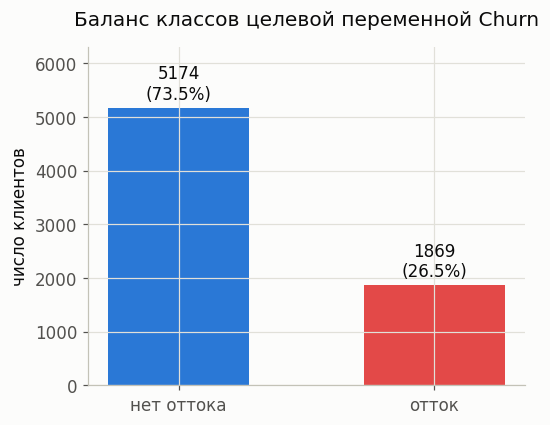

In [ ]:
# словарь для перевода значений Churn в подписи на графиках (сами данные не меняются)
churn_ru = {'No': 'нет оттока', 'Yes': 'отток'}

# считаем, сколько клиентов в каждом классе, и строим столбчатую диаграмму баланса классов
churn_counts = df['Churn'].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
x_labels = [churn_ru[v] for v in churn_counts.index]
ax.bar(x_labels, churn_counts.values, color=[PALETTE['blue'], PALETTE['red']], width=0.55)
ax.set_ylim(0, churn_counts.values.max() * 1.22)
# подписываем над каждым столбцом абсолютное число клиентов и их долю в процентах
for i, v in enumerate(churn_counts.values):
    ax.text(i, v + churn_counts.values.max() * 0.03, f'{v}\n({v/len(df):.1%})', ha='center', color='#0b0b0b')
ax.set_ylabel('число клиентов')
ax.set_title('Баланс классов целевой переменной Churn', pad=14)
savefig('01_churn_balance')

In [ ]:
# пункт 3 - преобразование атрибутов в числовые признаки
# customerID - это просто идентификатор клиента, для обучения модели он бесполезен, поэтому убираем
df_enc = df.drop(columns=['customerID']).copy()

# бинарные yes/no признаки -> 0/1
# перебираем каждый такой столбец и заменяем Yes на 1, а No на 0
binary_yn = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for c in binary_yn:
    df_enc[c] = (df_enc[c] == 'Yes').astype(int)

# gender обрабатывается отдельно, так как у него другие значения (Male/Female, а не Yes/No)
df_enc['gender'] = (df_enc['gender'] == 'Male').astype(int)

# производный признак: число подключенных дополнительных услуг.
# используется не сразу, а начиная с этапа оптимизации модели (пункт 8)
# для каждого клиента просто считаем, в скольких из 6 столбцов услуг стоит Yes
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                 'StreamingTV', 'StreamingMovies']
df_enc['num_services'] = (df[service_cols] == 'Yes').sum(axis=1)

# многозначные категориальные признаки -> one-hot кодирование
# (у каждого такого признака больше двух вариантов ответа, поэтому 0/1 здесь не подходит -
# get_dummies создает для каждого варианта значения отдельный бинарный столбец)
multi_cat = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
             'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
             'Contract', 'PaymentMethod']
df_enc = pd.get_dummies(df_enc, columns=multi_cat, drop_first=False)
# get_dummies создает столбцы типа bool (True/False) - переводим их в привычный 0/1
bool_cols = df_enc.select_dtypes(include='bool').columns
df_enc[bool_cols] = df_enc[bool_cols].astype(int)

# target - это то, что модель будет предсказывать (столбец Churn)
# feature_cols - все остальные столбцы, то есть признаки, по которым модель учится
target = 'Churn'
feature_cols = [c for c in df_enc.columns if c != target]
print('число признаков после кодирования:', len(feature_cols))
df_enc.head()

число признаков после кодирования: 41


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,1,0,0,0,0,1,0


In [ ]:
# таблица-памятка: какой тип признака как именно закодирован (используется в отчете как таблица 3)
encoding_table = pd.DataFrame({
    'Тип признака': ['Бинарный Yes/No', 'Бинарный gender', 'Многозначный категориальный',
                      'Количественный', 'Производный (число услуг)'],
    'Способ преобразования': ['0/1 (Yes -> 1)', '0/1 (Male -> 1)', 'one-hot кодирование (get_dummies)',
                               'без изменений (уже числовой)', 'сумма Yes по 6 столбцам услуг'],
    'Примеры атрибутов': ['Partner, Dependents, PhoneService, PaperlessBilling, Churn', 'gender',
                           'Contract, PaymentMethod, InternetService и др.',
                           'tenure, MonthlyCharges, TotalCharges', 'num_services']
})
encoding_table

,Тип признака,Способ преобразования,Примеры атрибутов
0,Бинарный Yes/No,0/1 (Yes -> 1),"Partner, Dependents, PhoneService, PaperlessBi..."
1,Бинарный gender,0/1 (Male -> 1),gender
2,Многозначный категориальный,one-hot кодирование (get_dummies),"Contract, PaymentMethod, InternetService и др."
3,Количественный,без изменений (уже числовой),"tenure, MonthlyCharges, TotalCharges"
4,Производный (число услуг),сумма Yes по 6 столбцам услуг,num_services


In [ ]:
# пункт 4 - описательный анализ данных
# describe() считает стандартную описательную статистику (среднее, минимум, максимум и т.д.)
# для трех количественных признаков; дисперсию describe() не выводит по умолчанию,
# поэтому она добавляется отдельной строкой через var()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
desc = df[num_cols].describe().T
desc['variance'] = df[num_cols].var()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,variance
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,603.17
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,905.41
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80,5138357.17


In [ ]:
# таблица со шкалами измерения признаков (номинальная, количественная и т.д.) - для отчета (таблица 5)
scales_table = pd.DataFrame({
    'Признак / переменная': ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen, Partner и др.',
                              'Contract, PaymentMethod, InternetService и др.', 'Churn'],
    'Тип и шкала': ['количественный, отношений (месяцы)', 'количественный, отношений (у.е./мес.)',
                     'количественный, отношений (у.е.)', 'номинальный бинарный',
                     'номинальный категориальный', 'номинальный бинарный (целевая переменная)'],
})
scales_table

,Признак / переменная,Тип и шкала
0,tenure,"количественный, отношений (месяцы)"
1,MonthlyCharges,"количественный, отношений (у.е./мес.)"
2,TotalCharges,"количественный, отношений (у.е.)"
3,"SeniorCitizen, Partner и др.",номинальный бинарный
4,"Contract, PaymentMethod, InternetService и др.",номинальный категориальный
5,Churn,номинальный бинарный (целевая переменная)


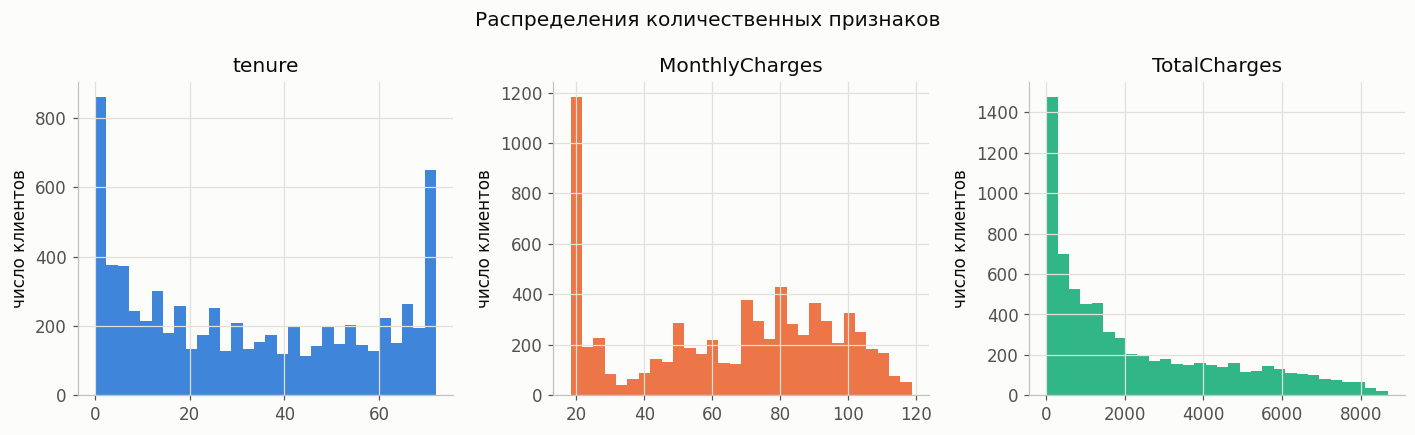

In [ ]:
# строим гистограммы распределения для каждого из трех количественных признаков,
# чтобы визуально увидеть их форму (есть ли перекос, несколько пиков и т.п.)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, color in zip(axes, num_cols, [PALETTE['blue'], PALETTE['orange'], PALETTE['aqua']]):
    ax.hist(df[col], bins=30, color=color, alpha=0.9)
    ax.set_title(col)
    ax.set_ylabel('число клиентов')
fig.suptitle('Распределения количественных признаков')
savefig('02_num_distributions')

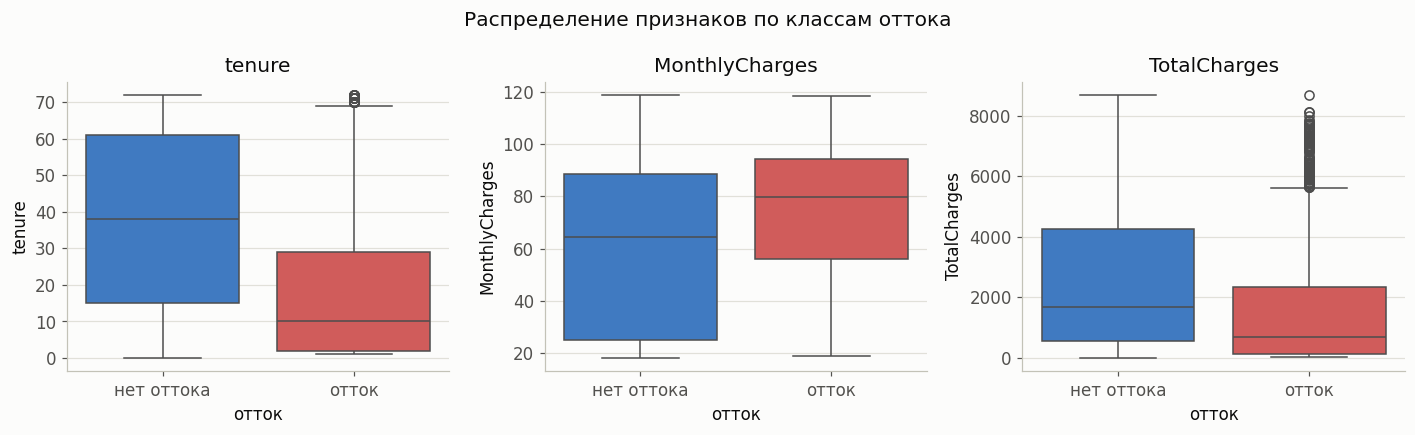

In [ ]:
# временный столбец только для подписи на графике - в df он не сохраняется
df_plot = df.copy()
df_plot['отток'] = df_plot['Churn'].map(churn_ru)

# boxplot (диаграмма размаха) показывает, как медиана и разброс значений признака
# отличаются у клиентов с оттоком и без него - по одному графику на признак
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='отток', y=col, data=df_plot, ax=ax, palette=[PALETTE['blue'], PALETTE['red']])
    ax.set_title(col)
fig.suptitle('Распределение признаков по классам оттока')
savefig('03_box_by_churn')

In [ ]:
# проверка на нормальность распределения (тест д'Агостино) для каждого количественного признака.
# если p_value меньше 0.05, распределение статистически значимо отличается от нормального
normality_results = {}
for c in num_cols:
    stat, p = stats.normaltest(df[c])
    normality_results[c] = {'statistic': round(stat, 2), 'p_value': p}
normality_table = pd.DataFrame(normality_results).T
normality_table

,statistic,p_value
tenure,76258.51,0.000000e+00
MonthlyCharges,11419.53,0.000000e+00
TotalCharges,808.60,2.604914e-176


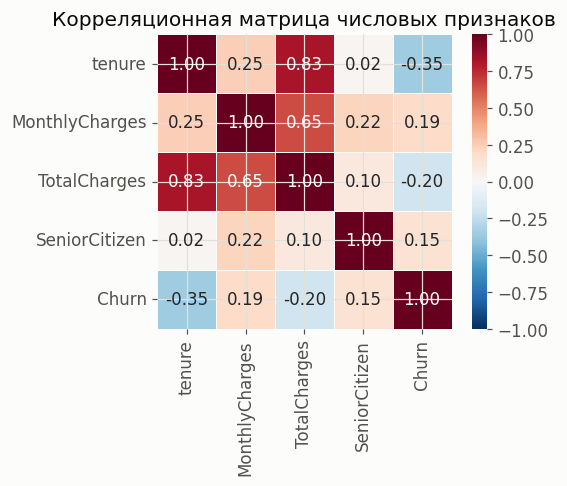

In [ ]:
# матрица корреляций между количественными признаками, SeniorCitizen и оттоком.
# Churn здесь временно переводится в 0/1 только для расчета корреляции, исходный df не меняется
corr_df = df[num_cols + ['SeniorCitizen']].copy()
corr_df['Churn'] = (df['Churn'] == 'Yes').astype(int)
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, linecolor='#fcfcfb', ax=ax)
ax.set_title('Корреляционная матрица числовых признаков')
savefig('04_correlation_matrix')

компонент для 90% объясненной дисперсии: 16 из 41


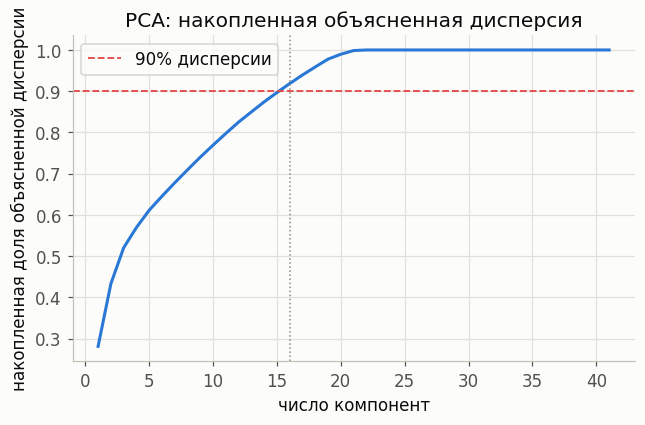

In [ ]:
# пункт 5 - методы обучения без учителя
# X_all - все признаки, y_all - целевая переменная (используются только в этом разделе,
# отдельно от train/val/test-выборок из пункта 6)
X_all = df_enc[feature_cols]
y_all = df_enc[target]

# перед pca и kmeans признаки обязательно нормируются (приводятся к одному масштабу),
# иначе признаки с большим диапазоном значений (например, TotalCharges) будут доминировать
scaler_u = StandardScaler()
X_scaled_all = scaler_u.fit_transform(X_all)

# pca без ограничения числа компонент - нужен, чтобы посмотреть, сколько компонент
# в принципе требуется, чтобы объяснить 90% дисперсии (разброса) данных
pca_full = PCA(random_state=SEED).fit(X_scaled_all)
explained = np.cumsum(pca_full.explained_variance_ratio_)
n_for_90 = int(np.searchsorted(explained, 0.90) + 1)
print(f'компонент для 90% объясненной дисперсии: {n_for_90} из {len(explained)}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(explained) + 1), explained, color=PALETTE['blue'], linewidth=2)
ax.axhline(0.9, color=PALETTE['red'], linestyle='--', linewidth=1.2, label='90% дисперсии')
ax.axvline(n_for_90, color='#898781', linestyle=':', linewidth=1)
ax.set_xlabel('число компонент')
ax.set_ylabel('накопленная доля объясненной дисперсии')
ax.set_title('PCA: накопленная объясненная дисперсия')
ax.legend()
savefig('05_pca_explained_variance')

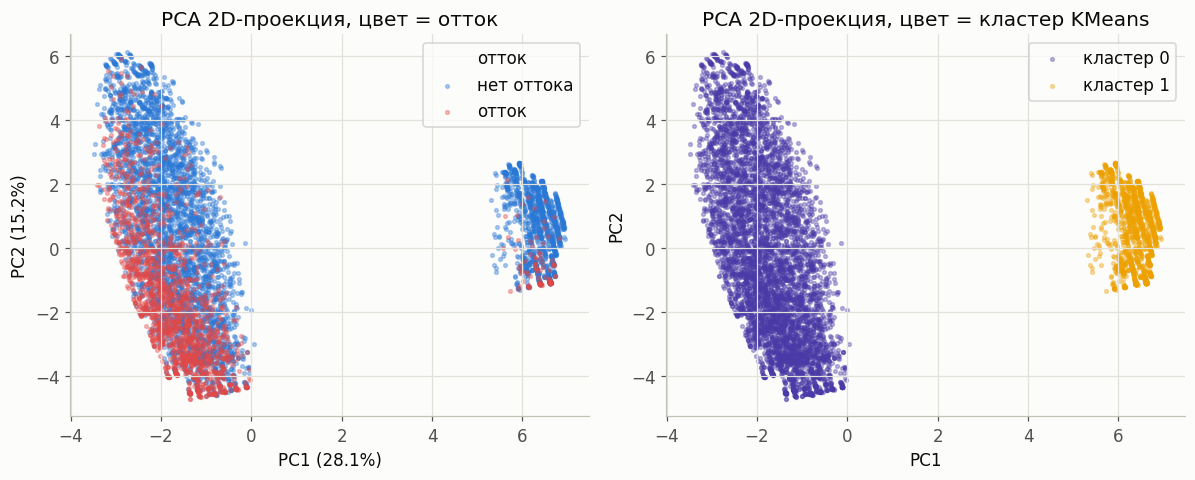

In [ ]:
# теперь берем pca ровно с двумя компонентами - это позволяет нарисовать данные
# на плоском двумерном графике и визуально оценить, насколько хорошо разделяются классы
pca2 = PCA(n_components=2, random_state=SEED)
X_pca2 = pca2.fit_transform(X_scaled_all)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# слева - точки раскрашены по реальному оттоку (Churn)
for cls, color, label in [(0, PALETTE['blue'], 'нет оттока'), (1, PALETTE['red'], 'отток')]:
    mask = (y_all == cls).values
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1], s=6, alpha=0.35, color=color, label=label)
axes[0].set_title('PCA 2D-проекция, цвет = отток')
axes[0].set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.1%})')
axes[0].legend(title='отток')

# справа - те же точки, но раскрашены по кластерам, которые нашел kmeans сам,
# без подсказки о реальном оттоке - сравнение этих двух графиков и есть суть анализа
kmeans = KMeans(n_clusters=2, n_init=10, random_state=SEED)
clusters = kmeans.fit_predict(X_scaled_all)
for cl, color in [(0, PALETTE['violet']), (1, PALETTE['yellow'])]:
    mask = clusters == cl
    axes[1].scatter(X_pca2[mask, 0], X_pca2[mask, 1], s=6, alpha=0.35, color=color, label=f'кластер {cl}')
axes[1].set_title('PCA 2D-проекция, цвет = кластер KMeans')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend()
savefig('06_pca_scatter')

In [ ]:
# численно сравниваем найденные kmeans-кластеры с реальным оттоком:
# ari и nmi показывают, насколько сильно кластеры совпадают с классами Churn (0 - никак не связаны),
# silhouette - насколько плотные и хорошо разделенные получились сами кластеры (независимо от Churn)
ari = adjusted_rand_score(y_all, clusters)
nmi = normalized_mutual_info_score(y_all, clusters)
sil_2 = silhouette_score(X_scaled_all, clusters, sample_size=2000, random_state=SEED)
print(f'KMeans (k=2) vs Churn: ARI = {ari:.4f}, NMI = {nmi:.4f}, silhouette = {sil_2:.4f}')

KMeans (k=2) vs Churn: ARI = -0.0654, NMI = 0.0570, silhouette = 0.2993


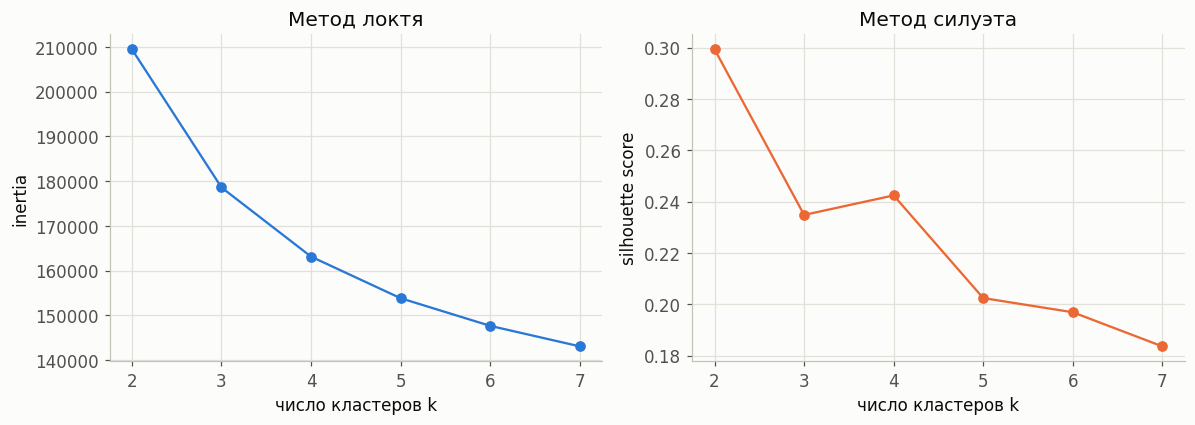

In [ ]:
# обоснование числа кластеров: elbow + silhouette для k = 2..7
# перебираем разное число кластеров k и для каждого запоминаем inertia (метод локтя)
# и silhouette score, чтобы выбрать оптимальное k не на глаз, а по объективным критериям
k_range = range(2, 8)
inertias, sils = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lab = km.fit_predict(X_scaled_all)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled_all, lab, sample_size=2000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# метод локтя: ищем точку, после которой inertia перестает резко падать
axes[0].plot(list(k_range), inertias, marker='o', color=PALETTE['blue'])
axes[0].set_xlabel('число кластеров k')
axes[0].set_ylabel('inertia')
axes[0].set_title('Метод локтя')

# метод силуэта: чем выше значение, тем лучше разделены кластеры при данном k
axes[1].plot(list(k_range), sils, marker='o', color=PALETTE['orange'])
axes[1].set_xlabel('число кластеров k')
axes[1].set_ylabel('silhouette score')
axes[1].set_title('Метод силуэта')
savefig('07_elbow_silhouette')

IsolationForest нашел 141 аномальных клиентов из 7043
доля оттока среди аномальных: 9.22%
доля оттока среди обычных: 26.89%


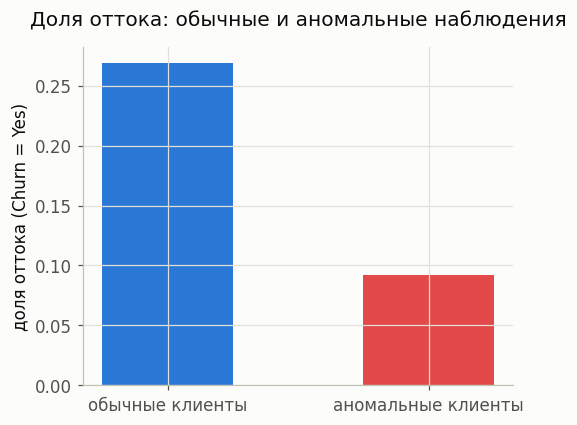

In [ ]:
# isolationforest ищет "аномальных" клиентов - тех, чье сочетание признаков сильно
# отличается от большинства. contamination=0.02 означает, что ожидаем около 2% таких клиентов
iso = IsolationForest(contamination=0.02, random_state=SEED)
anomaly_labels = iso.fit_predict(X_scaled_all)
n_anom = int((anomaly_labels == -1).sum())
# сравниваем долю оттока отдельно среди аномальных и среди обычных клиентов
anomaly_churn_rate = y_all[anomaly_labels == -1].mean()
normal_churn_rate = y_all[anomaly_labels == 1].mean()

print(f'IsolationForest нашел {n_anom} аномальных клиентов из {len(df)}')
print(f'доля оттока среди аномальных: {anomaly_churn_rate:.2%}')
print(f'доля оттока среди обычных: {normal_churn_rate:.2%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['обычные клиенты', 'аномальные клиенты'], [normal_churn_rate, anomaly_churn_rate],
       color=[PALETTE['blue'], PALETTE['red']], width=0.5)
ax.set_ylabel('доля оттока (Churn = Yes)')
ax.set_title('Доля оттока: обычные и аномальные наблюдения', pad=14)
savefig('08_isolation_forest')

In [ ]:
# пункт 6 - разделение данных, обучение нескольких моделей и первичное сравнение
# метрики качества зафиксированы заранее (roc-auc основная, f1 - на этапе оптимизации,
# полное обоснование - в отчете)

# базовый набор признаков (без num_services - этот признак добавляется только на этапе оптимизации)
base_feature_cols = [c for c in feature_cols if c != 'num_services']
X = df_enc[base_feature_cols]
y = df_enc[target]

# делим данные в два шага: сначала откладываем 30% под temp (validation + test вместе),
# затем temp делим пополам, получая в итоге train/validation/test = 70/15/15.
# stratify=y на каждом шаге следит, чтобы доля оттока была одинаковой во всех выборках
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

split_table = pd.DataFrame({
    'Выборка': ['Train', 'Validation', 'Test'],
    'Размер': [len(X_train), len(X_val), len(X_test)],
    'Доля оттока': [f'{y_train.mean():.2%}', f'{y_val.mean():.2%}', f'{y_test.mean():.2%}'],
    'Назначение': ['обучение моделей', 'выбор модели и подбор гиперпараметров', 'финальная независимая оценка']
})
split_table

,Выборка,Размер,Доля оттока,Назначение
0,Train,4930,26.53%,обучение моделей
1,Validation,1056,26.52%,выбор модели и подбор гиперпараметров
2,Test,1057,26.58%,финальная независимая оценка


In [ ]:
# scaler нормирует признаки - нужен только для Logistic Regression (остальные модели
# основаны на деревьях решений и от масштаба признаков не зависят)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# словарь со всеми моделями, которые сравниваются на этом шаге:
# dummy - наивная модель для сравнения (всегда предсказывает самый частый класс),
# остальные пять - реальные модели, среди них четыре ансамблевых (Random Forest, Gradient
# Boosting, AdaBoost, XGBoost) и одна линейная (Logistic Regression)
models = {
    'Dummy (most_frequent)': DummyClassifier(strategy='most_frequent', random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=SEED),
    'AdaBoost': AdaBoostClassifier(random_state=SEED),
    'XGBoost': XGBClassifier(random_state=SEED, eval_metric='logloss', n_jobs=-1),
}


# универсальная функция: обучает одну модель и сразу считает по ней весь набор метрик.
# используется дальше для каждой модели по очереди, чтобы не дублировать один и тот же код
def eval_model(model, X_tr, y_tr, X_ev, y_ev):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0
    pred = model.predict(X_ev)
    # proba - вероятность класса "отток", нужна для roc_auc и pr_auc (predict() дает только 0/1)
    proba = model.predict_proba(X_ev)[:, 1] if hasattr(model, 'predict_proba') else pred
    return {
        'accuracy': accuracy_score(y_ev, pred),
        'precision': precision_score(y_ev, pred, zero_division=0),
        'recall': recall_score(y_ev, pred, zero_division=0),
        'f1': f1_score(y_ev, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_ev, proba),
        'pr_auc': average_precision_score(y_ev, proba),
        'train_time_s': train_time,
    }, model

In [ ]:
# обучаем все модели из словаря по очереди и сохраняем метрики каждой на validation-выборке.
# Logistic Regression обучается на нормированных данных (X_train_s), остальные - на обычных
primary_results = {}
fitted_models = {}
for name, model in models.items():
    use_scaled = name == 'Logistic Regression'
    Xt = X_train_s if use_scaled else X_train
    Xv = X_val_s if use_scaled else X_val
    metrics, fitted = eval_model(model, Xt, y_train, Xv, y_val)
    primary_results[name] = metrics
    fitted_models[name] = fitted

# собираем все метрики в одну таблицу и сортируем по ROC-AUC (главная метрика сравнения)
primary_table = pd.DataFrame(primary_results).T
primary_table = primary_table.sort_values('roc_auc', ascending=False)
primary_table.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
Gradient Boosting,0.8021,0.6578,0.5286,0.5861,0.8474,0.6411,1.0507
Logistic Regression,0.8078,0.6498,0.5964,0.6220,0.8455,0.6287,0.0291
AdaBoost,0.7936,0.6211,0.5679,0.5933,0.8443,0.6384,0.3008
Random Forest,0.7746,0.5875,0.5036,0.5423,0.8181,0.5875,1.3666
XGBoost,0.7718,0.5759,0.5286,0.5512,0.8177,0.5985,0.1710
Dummy (most_frequent),0.7348,0.0000,0.0000,0.0000,0.5000,0.2652,0.0010


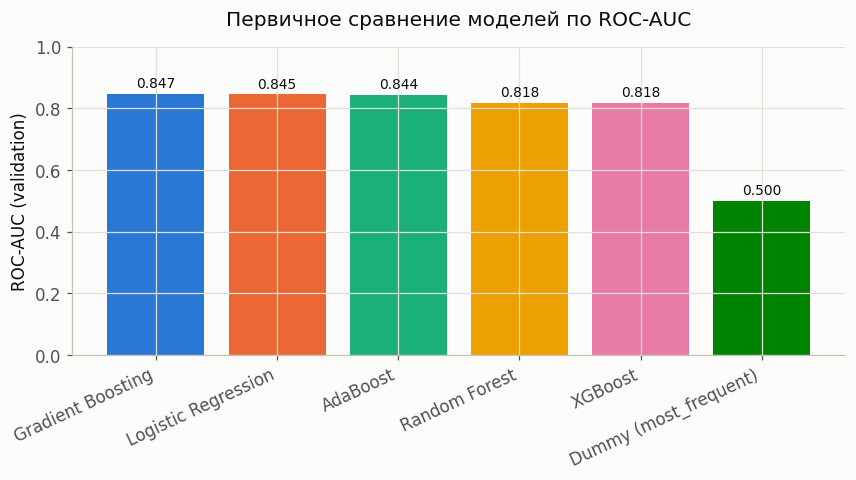

In [ ]:
# столбчатая диаграмма: сравниваем все модели по ROC-AUC на validation одним взглядом
fig, ax = plt.subplots(figsize=(8, 4.5))
order = primary_table.index.tolist()
colors = CAT_COLORS[:len(order)]
bars = ax.bar(order, primary_table.loc[order, 'roc_auc'], color=colors)
ax.set_ylabel('ROC-AUC (validation)')
ax.set_title('Первичное сравнение моделей по ROC-AUC', pad=14)
ax.set_ylim(0, 1.0)
plt.xticks(rotation=25, ha='right')
# подписываем точное значение метрики над каждым столбцом
for b, v in zip(bars, primary_table.loc[order, 'roc_auc']):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)
savefig('09_primary_comparison')

In [ ]:
# пункт 7 - выбор перспективной модели и подбор гиперпараметров
# берем модель с лучшим ROC-AUC из предыдущего пункта - именно ее дальше настраиваем
best_name_before_tuning = primary_table.index[0]
print('модель, выбранная для подбора гиперпараметров:', best_name_before_tuning)

# сетка гиперпараметров для перебора: GridSearchCV попробует все комбинации значений
# из этого словаря и для каждой посчитает качество по кросс-валидации
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.03, 0.1, 0.2],
    'min_samples_leaf': [1, 20],
}
print('всего комбинаций:', np.prod([len(v) for v in param_grid.values()]))

модель, выбранная для подбора гиперпараметров: Gradient Boosting
всего комбинаций: 54


In [ ]:
# stratifiedkfold делит train-выборку на 3 фолда, сохраняя долю оттока в каждом -
# это и есть 3-кратная кросс-валидация, упомянутая в отчете
gb = GradientBoostingClassifier(random_state=SEED, subsample=0.8)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
# gridsearchcv сам обучает модель на каждой комбинации параметров и каждом фолде,
# а затем выбирает комбинацию с лучшим средним ROC-AUC по кросс-валидации
grid = GridSearchCV(gb, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)

t0 = time.time()
grid.fit(X_train, y_train)
grid_time = time.time() - t0

print(f'grid search завершен за {grid_time:.1f} с, {len(grid.cv_results_["params"])} комбинаций x 3 фолда')
print('лучшие параметры:', grid.best_params_)
print(f'лучший CV ROC-AUC: {grid.best_score_:.4f}')

grid search завершен за 177.0 с, 54 комбинаций x 3 фолда
лучшие параметры: {'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 20, 'n_estimators': 300}
лучший CV ROC-AUC: 0.8476


In [ ]:
# gb_tuned - модель с лучшими найденными гиперпараметрами, GridSearchCV обучает ее
# на всей train-выборке автоматически (best_estimator_)
gb_tuned = grid.best_estimator_
proba_val_tuned = gb_tuned.predict_proba(X_val)[:, 1]
pred_val_tuned = gb_tuned.predict(X_val)

# считаем те же метрики, что и раньше, чтобы сравнить модель до и после подбора параметров
tuned_metrics = {
    'accuracy': accuracy_score(y_val, pred_val_tuned),
    'precision': precision_score(y_val, pred_val_tuned, zero_division=0),
    'recall': recall_score(y_val, pred_val_tuned, zero_division=0),
    'f1': f1_score(y_val, pred_val_tuned, zero_division=0),
    'roc_auc': roc_auc_score(y_val, proba_val_tuned),
    'pr_auc': average_precision_score(y_val, proba_val_tuned),
}
pd.DataFrame({'Gradient Boosting (baseline)': primary_results['Gradient Boosting'],
              'Gradient Boosting (tuned)': tuned_metrics}).round(4)

,Gradient Boosting (baseline),Gradient Boosting (tuned)
accuracy,0.8021,0.8011
precision,0.6578,0.6549
recall,0.5286,0.5286
f1,0.5861,0.5850
roc_auc,0.8474,0.8516
pr_auc,0.6411,0.6556
train_time_s,1.0507,NaN


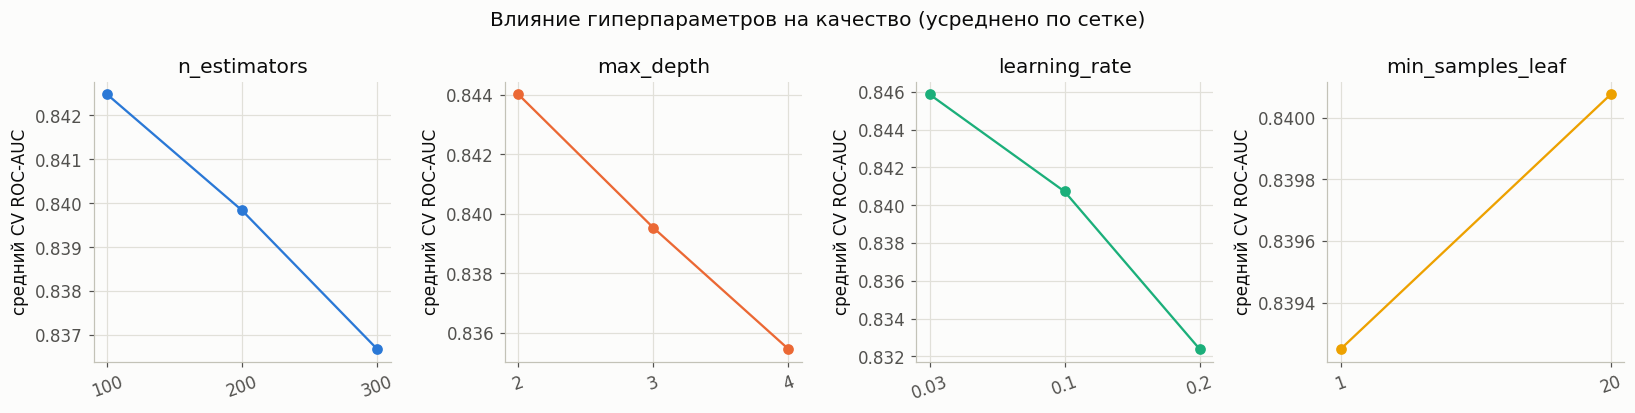

In [ ]:
# для каждого гиперпараметра отдельно смотрим, как средний CV ROC-AUC меняется
# в зависимости от его значения (усредняя по всем остальным параметрам сетки)
cvres = pd.DataFrame(grid.cv_results_)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, p, color in zip(axes, param_grid.keys(), CAT_COLORS):
    g = cvres.groupby(f'param_{p}')['mean_test_score'].mean()
    ax.plot(g.index.astype(str), g.values, marker='o', color=color)
    ax.set_title(p)
    ax.set_ylabel('средний CV ROC-AUC')
    ax.tick_params(axis='x', rotation=20)
fig.suptitle('Влияние гиперпараметров на качество (усреднено по сетке)')
savefig('10_grid_search_params')

In [ ]:
# пункт 8 - оптимизация модели
# три направления: признак num_services, взвешивание классов, подбор порога по f1
X_opt = df_enc[feature_cols]  # уже включает num_services
X_train_opt = X_opt.loc[X_train.index]
X_val_opt = X_opt.loc[X_val.index]
X_test_opt = X_opt.loc[X_test.index]

# compute_sample_weight сам считает вес для каждого объекта так, чтобы редкий класс (отток)
# во время обучения "весил" больше - это и есть взвешивание классов
sw_train = compute_sample_weight(class_weight='balanced', y=y_train)

# обучаем Gradient Boosting с лучшими параметрами из GridSearchCV, но уже на расширенном
# наборе признаков (с num_services) и с весами sample_weight
best_params = grid.best_params_
gb_opt = GradientBoostingClassifier(random_state=SEED, subsample=0.8, **best_params)
gb_opt.fit(X_train_opt, y_train, sample_weight=sw_train)

proba_val_opt = gb_opt.predict_proba(X_val_opt)[:, 1]

In [ ]:
# перебираем 181 возможный порог классификации от 0.05 до 0.95 и для каждого считаем f1 -
# по умолчанию порог всегда 0.5, но при дисбалансе классов лучший результат часто дает другое значение
thresholds = np.linspace(0.05, 0.95, 181)
f1_scores = [f1_score(y_val, (proba_val_opt >= t).astype(int), zero_division=0) for t in thresholds]
# находим порог, при котором f1 максимален
best_t = float(thresholds[int(np.argmax(f1_scores))])
print(f'оптимальный порог по F1 на validation: {best_t:.2f}')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(thresholds, f1_scores, color=PALETTE['blue'], linewidth=2)
ax.axvline(best_t, color=PALETTE['red'], linestyle='--', linewidth=1.2,
           label=f'оптимальный порог = {best_t:.2f}')
ax.axvline(0.5, color='#898781', linestyle=':', linewidth=1, label='порог по умолчанию = 0.50')
ax.set_xlabel('порог классификации')
ax.set_ylabel('F1 (validation)')
ax.set_title('Подбор порога классификации по F1')
ax.legend()
savefig('11_threshold_tuning')

In [ ]:
# применяем найденный оптимальный порог вместо стандартного 0.5 и пересчитываем метрики
pred_val_opt = (proba_val_opt >= best_t).astype(int)
opt_metrics = {
    'accuracy': accuracy_score(y_val, pred_val_opt),
    'precision': precision_score(y_val, pred_val_opt, zero_division=0),
    'recall': recall_score(y_val, pred_val_opt, zero_division=0),
    'f1': f1_score(y_val, pred_val_opt, zero_division=0),
    'roc_auc': roc_auc_score(y_val, proba_val_opt),
    'pr_auc': average_precision_score(y_val, proba_val_opt),
}

# сводим в одну таблицу метрики до всей оптимизации (tuned) и после нее (optimized)
compare_opt = pd.DataFrame({
    'Gradient Boosting (tuned, порог 0.5)': tuned_metrics,
    'Gradient Boosting (optimized, порог %.2f)' % best_t: opt_metrics,
}).round(4)
compare_opt

In [ ]:
# наглядно сравниваем метрики tuned и optimized парами столбиков рядом друг с другом
fig, ax = plt.subplots(figsize=(7.5, 4.5))
metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']
x = np.arange(len(metrics_to_plot))
width = 0.35
ax.bar(x - width/2, [tuned_metrics[m] for m in metrics_to_plot], width,
       label='до оптимизации (tuned)', color=PALETTE['blue'])
ax.bar(x + width/2, [opt_metrics[m] for m in metrics_to_plot], width,
       label='после оптимизации', color=PALETTE['orange'])
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, rotation=20, ha='right')
ax.set_ylim(0, 1.0)
ax.set_title('Эффект оптимизации модели (validation)', pad=14)
ax.legend()
savefig('12_optimization_effect')

In [ ]:
# пункт 9 - представление результатов моделирования, итоговые выводы и перспективы
# финальная оценка один раз на test, которая нигде раньше не использовалась
proba_test = gb_opt.predict_proba(X_test_opt)[:, 1]
pred_test = (proba_test >= best_t).astype(int)

test_metrics = {
    'accuracy': accuracy_score(y_test, pred_test),
    'precision': precision_score(y_test, pred_test, zero_division=0),
    'recall': recall_score(y_test, pred_test, zero_division=0),
    'f1': f1_score(y_test, pred_test, zero_division=0),
    'roc_auc': roc_auc_score(y_test, proba_test),
    'pr_auc': average_precision_score(y_test, proba_test),
}
pd.DataFrame({'Test': test_metrics}).round(4)

In [ ]:
# classification_report печатает precision/recall/f1 сразу по обоим классам плюс общую сводку.
# названия классов переведены, но заголовки столбцов (precision, recall, f1-score, support)
# в самой функции classification_report зашиты на английском и не настраиваются
print(classification_report(y_test, pred_test, target_names=['нет оттока', 'отток']))

In [ ]:
# confusion_matrix (матрица ошибок) показывает, сколько клиентов правильно и неправильно
# отнесены к каждому классу - по ней видно не только точность, но и характер ошибок модели
cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5, 4.3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['нет оттока', 'отток'], yticklabels=['нет оттока', 'отток'], ax=ax)
ax.set_xlabel('предсказание')
ax.set_ylabel('истинный класс')
ax.set_title('Матрица ошибок на test-выборке', pad=14)
savefig('13_confusion_matrix')

In [ ]:
# roc-кривая и precision-recall-кривая на test-выборке - показывают качество модели
# при всех возможных порогах сразу, а не только при одном конкретном значении
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, color=PALETTE['blue'], linewidth=2, label=f'ROC-AUC = {test_metrics["roc_auc"]:.3f}')
axes[0].plot([0, 1], [0, 1], color='#898781', linestyle='--', linewidth=1)
axes[0].set_xlabel('доля ложноположительных (FPR)')
axes[0].set_ylabel('доля истинноположительных (TPR)')
axes[0].set_title('ROC-кривая (test)')
axes[0].legend()

axes[1].plot(rec, prec, color=PALETTE['orange'], linewidth=2, label=f'PR-AUC = {test_metrics["pr_auc"]:.3f}')
axes[1].axhline(y_test.mean(), color='#898781', linestyle='--', linewidth=1, label='базовый уровень')
axes[1].set_xlabel('полнота (recall)')
axes[1].set_ylabel('точность (precision)')
axes[1].set_title('Precision-Recall кривая (test)')
axes[1].legend()
savefig('14_roc_pr_curves')

In [ ]:
# сводим в одну таблицу roc-auc всех моделей: базовые модели из пункта 6 (кроме dummy) плюс
# tuned и optimized версии Gradient Boosting, чтобы увидеть общий путь улучшения качества
final_ranking = {k: v['roc_auc'] for k, v in primary_results.items() if k != 'Dummy (most_frequent)'}
final_ranking['Gradient Boosting (tuned)'] = tuned_metrics['roc_auc']
final_ranking['Gradient Boosting (optimized)'] = opt_metrics['roc_auc']
final_ranking_table = pd.DataFrame.from_dict(final_ranking, orient='index', columns=['ROC-AUC (validation)'])
final_ranking_table = final_ranking_table.sort_values('ROC-AUC (validation)', ascending=False)
final_ranking_table.round(4)

In [ ]:
# горизонтальная столбчатая диаграмма для той же итоговой таблицы - удобнее читать,
# когда подписи моделей длинные
fig, ax = plt.subplots(figsize=(8.5, 4.5))
order = final_ranking_table.index.tolist()
colors = (CAT_COLORS * 2)[:len(order)]
bars = ax.barh(order[::-1], final_ranking_table['ROC-AUC (validation)'].values[::-1], color=colors[::-1])
ax.set_xlabel('ROC-AUC (validation)')
ax.set_title('Итоговое сравнение всех моделей', pad=14)
ax.set_xlim(0.75, 0.87)
for b, v in zip(bars, final_ranking_table['ROC-AUC (validation)'].values[::-1]):
    ax.text(v + 0.002, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
savefig('15_final_ranking')

In [ ]:
# интерпретация модели: feature importance, permutation importance, shap
# feature_importances_ - это встроенная в саму модель оценка важности признаков,
# она считается автоматически во время обучения дерева решений
fi = pd.Series(gb_opt.feature_importances_, index=X_train_opt.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(fi.index[::-1], fi.values[::-1], color=PALETTE['blue'])
ax.set_xlabel('feature importance (встроенная в модель)')
ax.set_title('Важность признаков: Gradient Boosting', pad=14)
savefig('16_feature_importance')

In [ ]:
# permutation importance работает иначе: библиотека по очереди "перемешивает" значения
# каждого признака и смотрит, насколько сильно из-за этого падает ROC-AUC на validation -
# чем сильнее падение, тем важнее был признак. n_repeats=10 означает, что каждый признак
# перемешивается 10 раз подряд и результат усредняется, чтобы оценка была устойчивее
perm = permutation_importance(gb_opt, X_val_opt, y_val, n_repeats=10, random_state=SEED,
                               scoring='roc_auc', n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_val_opt.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(perm_s.index[::-1], perm_s.values[::-1], color=PALETTE['aqua'])
ax.set_xlabel('permutation importance (падение ROC-AUC)')
ax.set_title('Важность признаков: permutation importance (validation)', pad=14)
savefig('17_permutation_importance')

In [ ]:
# shap - третий, самый детальный способ интерпретации: для каждого клиента из выборки
# и каждого признака считается вклад именно этого значения признака в итоговое предсказание.
# TreeExplainer работает быстро именно для моделей на основе деревьев (как Gradient Boosting)
explainer = shap.TreeExplainer(gb_opt)
# берем случайную выборку из 500 клиентов test-выборки, чтобы расчет не занимал слишком много времени
X_shap_sample = X_test_opt.sample(n=min(500, len(X_test_opt)), random_state=SEED)
shap_values = explainer.shap_values(X_shap_sample)

# summary_plot показывает сразу и важность признаков (сверху вниз), и направление влияния
# (цвет точки - высокое или низкое значение признака, положение - в какую сторону это сдвигает предсказание)
shap.summary_plot(shap_values, X_shap_sample, show=False, max_display=12)
plt.title('Интерпретация модели: SHAP (test, выборка 500 клиентов)')
plt.xlabel('вклад в предсказание (SHAP value)')

# у shap ось цветовой шкалы подписана на английском (Feature value, High, Low) -
# это часть самой библиотеки, переписываем подписи вручную поверх готового графика
fig_cur = plt.gcf()
for a in fig_cur.axes:
    if a.get_ylabel() == 'Feature value':
        a.set_ylabel('значение признака')
        a.set_yticks([0, 1])
        a.set_yticklabels(['низкое', 'высокое'])

savefig('18_shap_summary')

In [ ]:
# короткая итоговая таблица с финальными метриками на test-выборке - удобно вставить
# в самый конец презентации или отчета как единственную "последнюю строку" всей работы
final_summary = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'PR-AUC'],
    'Значение на test': [f"{test_metrics['accuracy']:.4f}", f"{test_metrics['precision']:.4f}",
                          f"{test_metrics['recall']:.4f}", f"{test_metrics['f1']:.4f}",
                          f"{test_metrics['roc_auc']:.4f}", f"{test_metrics['pr_auc']:.4f}"]
})
final_summary